## Judging a search

A search's winner is the best of many noisy scores, so its in-sample Sharpe is biased
upward, and by more the more the search looks. `probatum.stats` judges the winner against
every trial the search took: the deflated Sharpe against a null search, the effective
number of independent trials, the probability of backtest overfitting, White's Reality
Check and Hansen's SPA, and the minimum backtest length. A random search of 100 crossings
on hourly Bitcoin bars of 2024 and 2025.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import numpy
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 2.0.0, exchange-router 3.0.1


### The bars

In [2]:
PATH = pathlib.Path("../bars/binance-spot-btcusdt-1h-2024-2025")

if PATH.exists():
    data = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        data = probatum.Data.from_router(router, exchange="binance", market="spot",
                                         interval="1h", symbols=["BTCUSDT"],
                                         start="2024-01-01", end="2025-12-31")
    data.save(path=PATH)

data

Data(BTCUSDT, 1h, 17544 bars from 2024-01-01 00:00 to 2025-12-31 23:00)

### The search and its null

The searched study, and a null: another random search of the same policy over the same
space, with another seed, whose spread of Sharpes says what the best of so many trials
reaches by luck.

In [3]:
def crossing(data, fast, slow):
    up   = probatum.ta.ema(data.close, length=fast)
    down = probatum.ta.ema(data.close, length=slow)
    return numpy.where(up > down, 1.0, 0.0)


space = {"fast": probatum.Int(low=6, high=72),
         "slow": probatum.Int(low=96, high=528)}

study = probatum.search(crossing, space=space, data=data, venue="binance_spot",
                        sampler="random", trials=100, holdout=0.3, seed=7)
null  = probatum.search(crossing, space=space, data=data, venue="binance_spot",
                        sampler="random", trials=100, holdout=0.3, seed=8)

study.summary(null=null)

value low high level method why_none
best              2.08                               
deflated_sharpe   0.92                               
deflated_cluster  0.99                               
null_mean         1.58                               
overfitting       0.37                               
overfitting_loss  0.13                               
holdout                                             1
buy_and_hold                                        1

                               value
policy                      crossing
venue                   binance_spot
data                 spot:BTCUSDT 1h
objective                     sharpe
direction                   maximize
sampler                       random
trials                           100
first                     2024-01-01
last                      2025-05-26
held out   the last 30% (5,263 bars)
looks                              0
best fast                         55
best slow                        368

                                        why_none
1  not yet run; evaluate_holdout() spends a look

### The deflated Sharpe

The winner's probabilistic Sharpe against the threshold the best of that many trials
reaches by luck, the trials' Sharpes spread as the null's are, and again against the
effective number of trials.

In [4]:
study.deflated_sharpe(null)

,value,threshold,trials,spread,null_trials,sharpe,effective,effective_value,effective_threshold,lag,floored,count,descriptive
Deflated,0.924496,0.870702,100,0.344069,100,2.084621,2,0.991692,0.386648,8,True,12280,False


### How many trials were really run

A hundred crossings of nearby lengths trade almost alike. The clustering of their returns
counts the trials that are independent of one another.

In [5]:
study.effective_trials()

,clusters
trial,
0,0
1,1
2,0
3,0
4,1
...,...
95,1
96,0
97,0


### The probability of backtest overfitting

The in-sample bars cut into 16 blocks and halved every one of 12,870 ways: how often the
best trial of one half ranks below the median in the other, and how often it loses there.

In [6]:
study.overfitting()

,probability,loss,trials,blocks,dropped,objective,direction,descriptive
Overfitting,0.370396,0.128205,100,16,8,sharpe,maximize,False


### Does any trial beat cash

White's Reality Check and Hansen's SPA test, on one shared bootstrap of the bars, whether
the best trial's growth beats holding cash, or here buying and holding. Each resample
draws every trial's returns again, so 250 of them rather than the default 1,000 keep this
cell to a minute.

In [7]:
print(study.reality_check(resamples=250, seed=7))

study.reality_check(benchmark="buy_and_hold", resamples=250, seed=7)

                   p  statistic
reality check  0.060   0.008556
spa            0.048   2.309591

                value
best               16
block        3.489224
resamples         250
trials            100
excluded            0
benchmark        cash
descriptive     False


p  statistic
reality check  0.708   0.000029
spa            0.708   0.007013

                          value
best                         16
block                   1.53324
resamples                   250
trials                      100
excluded                      0
benchmark    buying and holding
descriptive               False

### The span luck needs

The years over which the expected best of this many trials with no skill falls to the
winner's Sharpe.

In [8]:
study.min_backtest_length()

,years,trials,sharpe,series_years
BacktestLength,1.473648,100,2.084621,1.401826


### The trials beside their null

The Sharpe of every trial of the search and of the null, with the winner's and the
threshold the deflation sets.

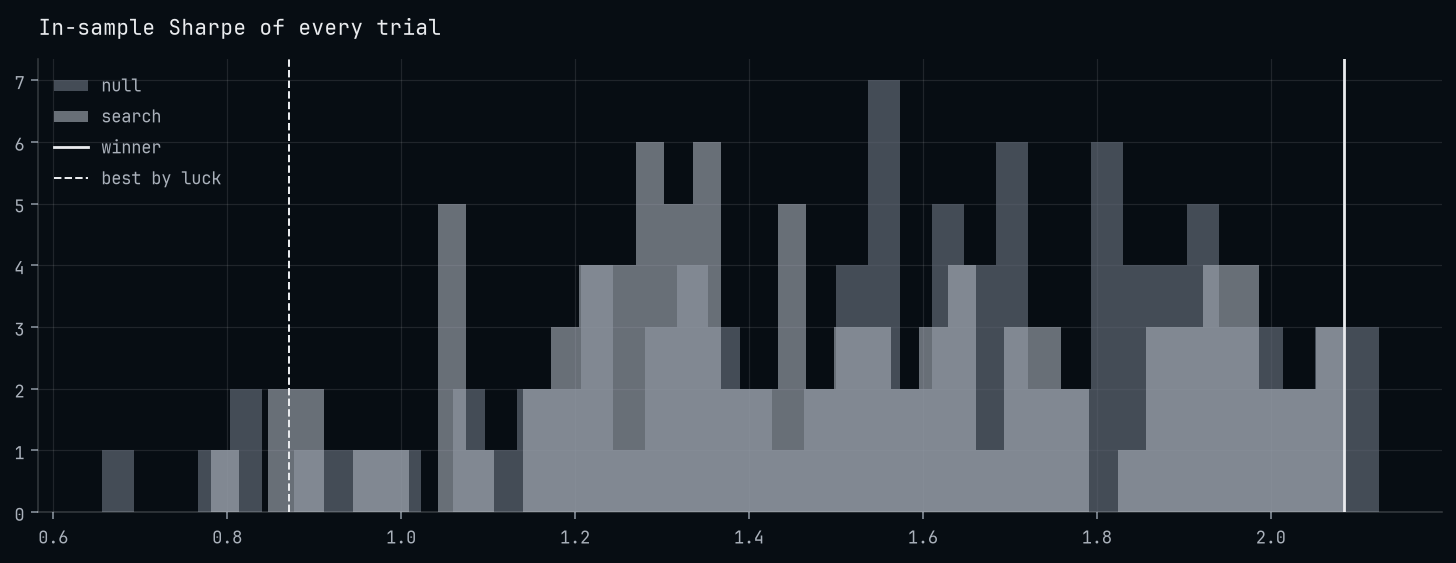

In [9]:
deflated = study.deflated_sharpe(null)

figure, axes = matplotlib.pyplot.subplots(figsize=(10.0, 3.8))
axes.hist(null.trials.to_pandas()["score"], bins=40, color="C3", alpha=0.7, label="null")
axes.hist(study.trials.to_pandas()["score"], bins=40, color="C1", alpha=0.6,
          label="search")
axes.axvline(x=deflated.sharpe, color="C0", linewidth=1.4, label="winner")
axes.axvline(x=deflated.threshold, color="C0", linestyle="--", linewidth=1.0,
             label="best by luck")
axes.set_title(label="In-sample Sharpe of every trial")
axes.legend(loc="upper left")
matplotlib.pyplot.show()

### After the look

Once the holdout is run, the winner's score less its holdout's is its decay, and its run cut
into four stretches says how evenly the in-sample score was earned.

In [10]:
held = study.evaluate_holdout()

print(study.decay())

study.consistency()

                            first                      last    fitted  \
window                                                                  
holdout 2025-05-26 17:00:00+00:00 2025-12-31 23:00:00+00:00  2.084621   

           earned      gaps  
window                       
holdout -1.190665  3.275286  

              value
mean       3.275286
objective    sharpe
direction  maximize


,scores
0,2.014646
1,0.782737
2,3.311740
3,1.743838
,value
unit,stretches
break_even,0.0
share,1.0
objective,sharpe
direction,maximize
